In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [2]:
df=pd.read_csv("Titanic-Dataset.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


<Axes: >

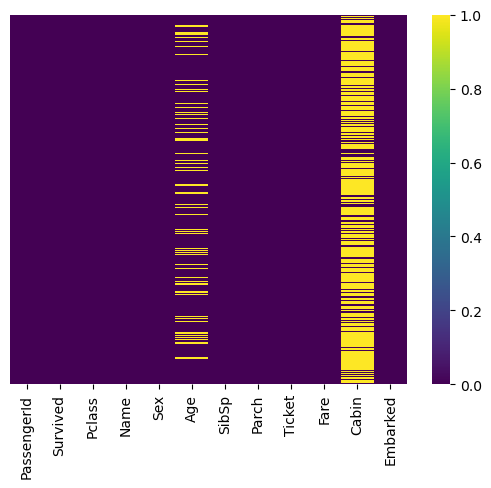

In [6]:
# Count missing values
print("Missing Values:")
print(df.isnull().sum())

sns.heatmap(df.isnull(),yticklabels=False,cmap='viridis' )


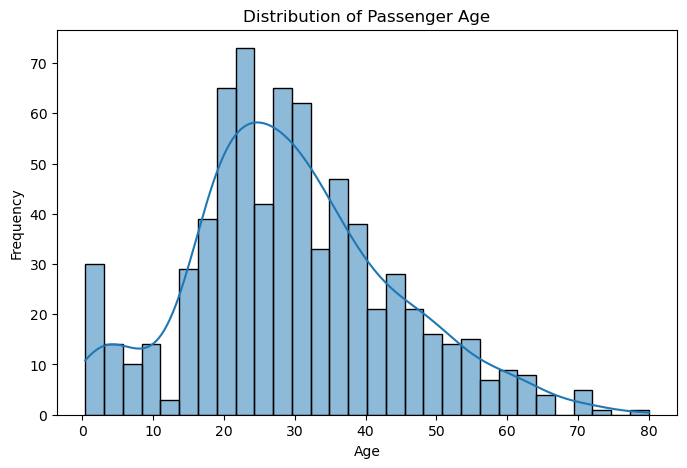

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Age'].dropna(), bins=30, kde=True)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

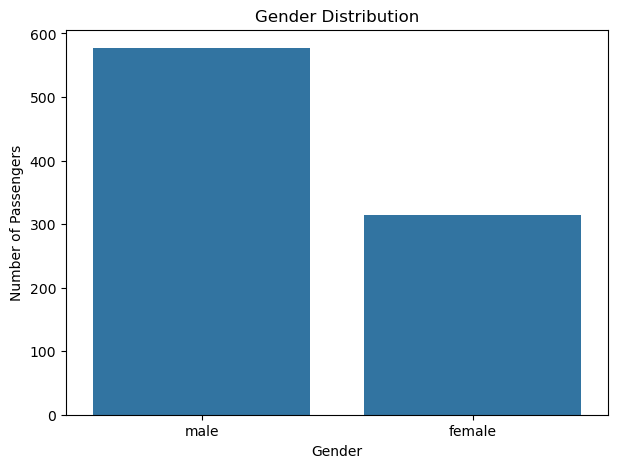

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sex')

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

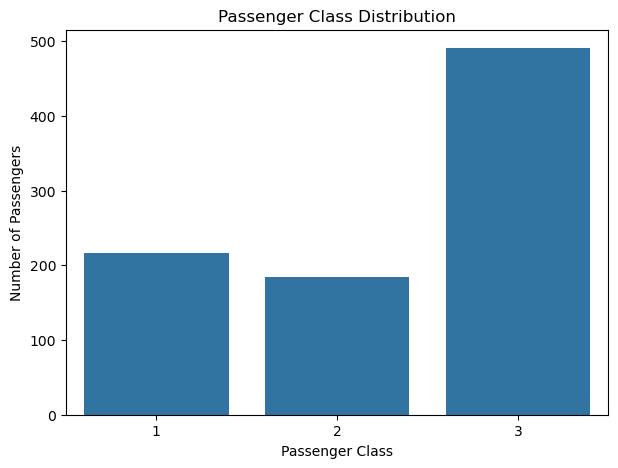

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Pclass')

plt.title("Passenger Class Distribution")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

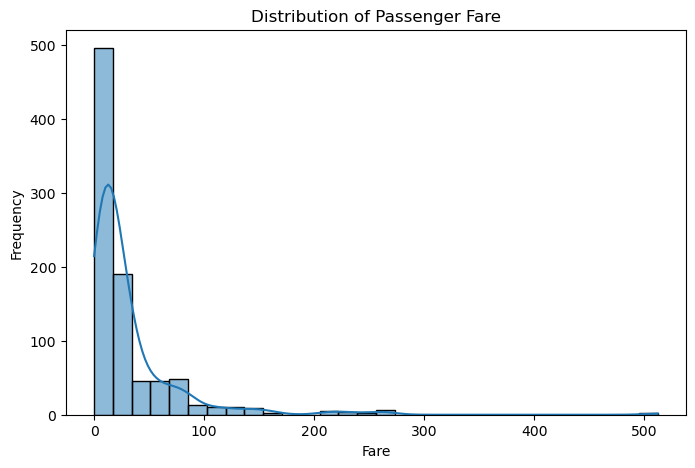

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Fare'], bins=30, kde=True)

plt.title("Distribution of Passenger Fare")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.show()

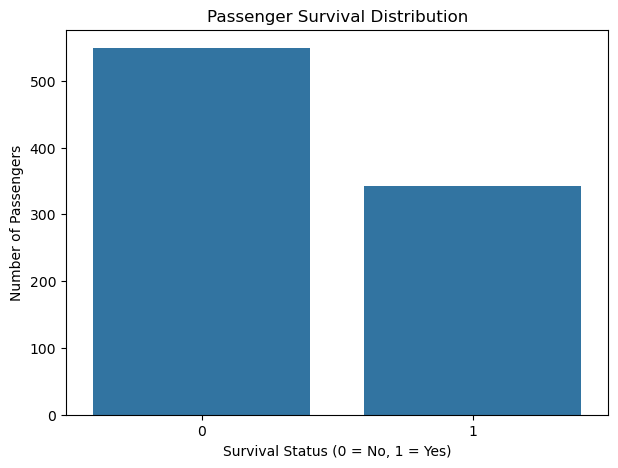

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Survived')

plt.title("Passenger Survival Distribution")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

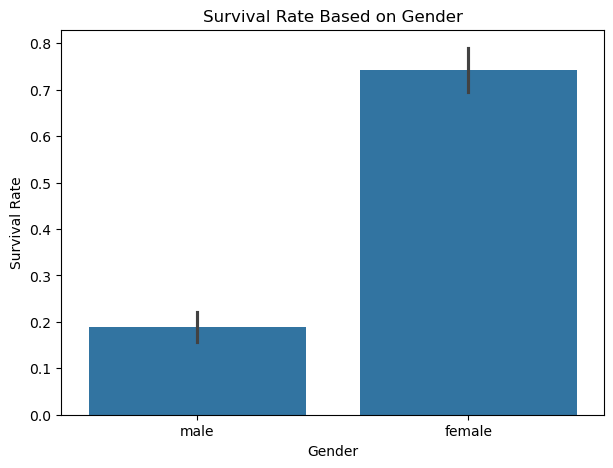

In [12]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x='Sex', y='Survived')

plt.title("Survival Rate Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

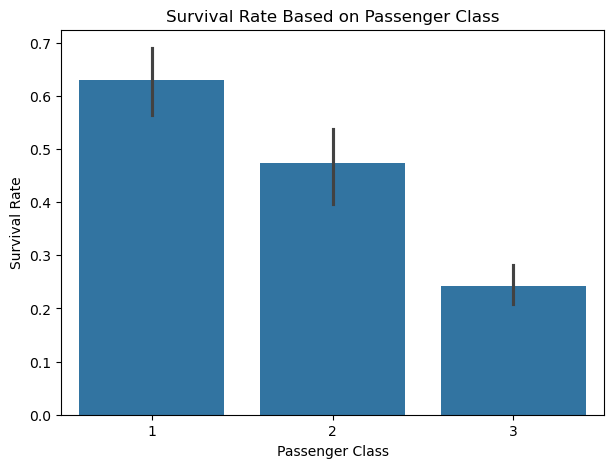

In [13]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x='Pclass', y='Survived')

plt.title("Survival Rate Based on Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

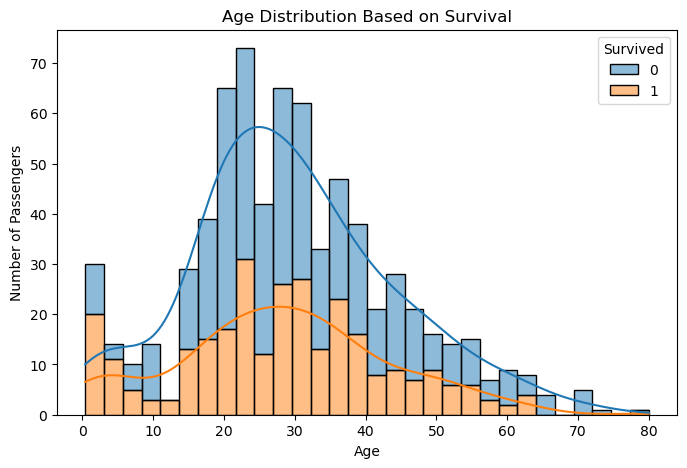

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Survived',
    bins=30,
    kde=True,
    multiple='stack'
)

plt.title("Age Distribution Based on Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

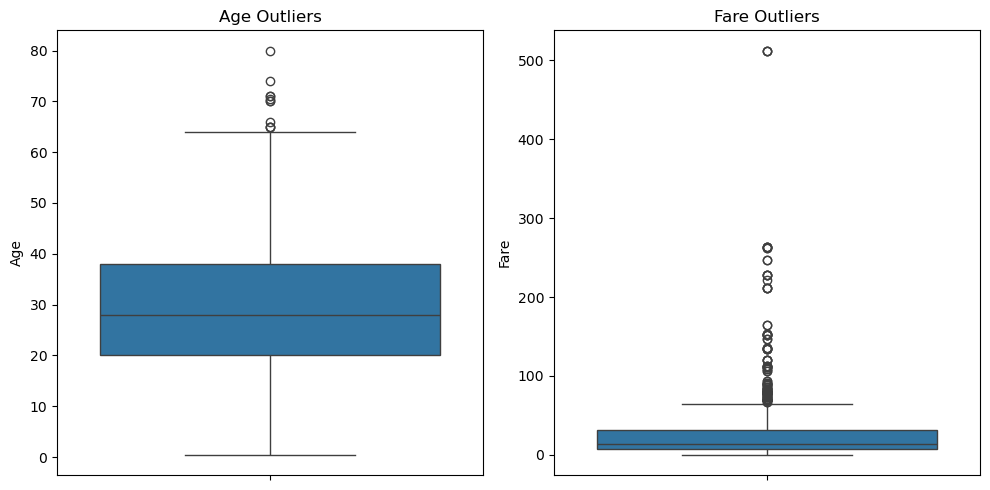

In [15]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['Age'])
plt.title("Age Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Fare'])
plt.title("Fare Outliers")

plt.tight_layout()
plt.show()

In [16]:
df['Sex_Num']=df['Sex'].map({
    'male':0,
    'female':1
})

In [17]:
numeric_cols=['Survived','Sex_Num','Pclass','Fare','Age','Parch', 'SibSp']

<Axes: >

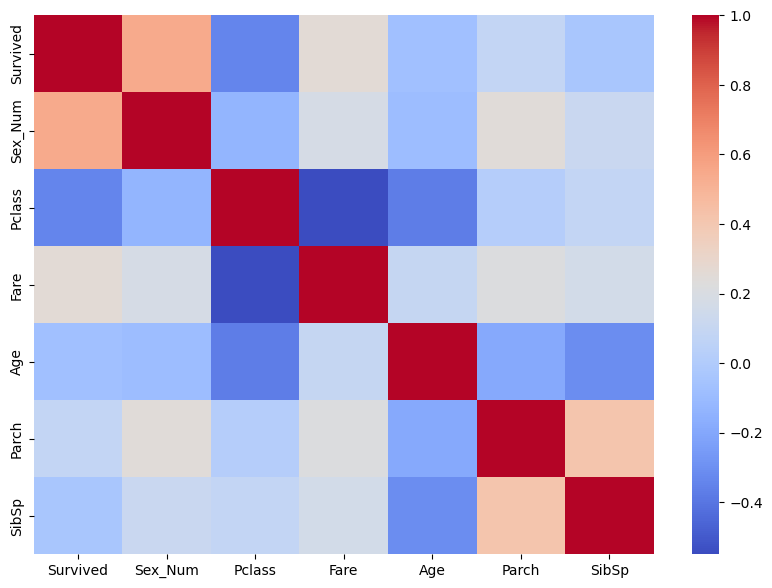

In [18]:
corr=df[numeric_cols].corr()
plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    cmap='coolwarm'
)

<Axes: xlabel='Pclass', ylabel='Age'>

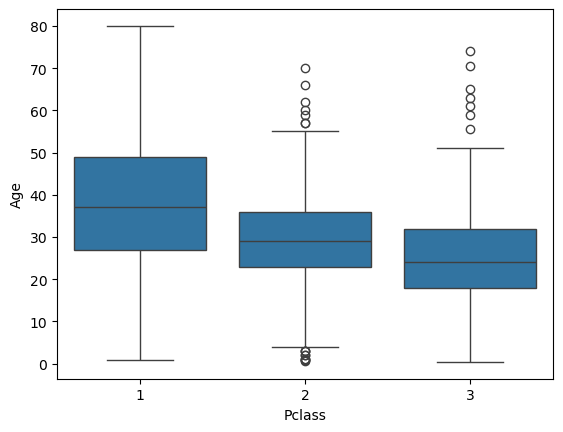

In [19]:
#Age and Cabin has a high number of missing data, we can fill missing ages with avg age from PcLass
sns.boxplot(data=df,x='Pclass', y='Age')

In [20]:
class1Age=df[df['Pclass']==1]['Age'].dropna().mean()
class2Age=df[df['Pclass']==2]['Age'].dropna().mean()
class3Age=df[df['Pclass']==3]['Age'].dropna().mean()

print("Avg Age of passengers from class 1",class1Age)
print("Avg Age of passengers from class 2",class2Age)
print("Avg Age of passengers from class 3",class3Age)


Avg Age of passengers from class 1 38.233440860215055
Avg Age of passengers from class 2 29.87763005780347
Avg Age of passengers from class 3 25.14061971830986


In [21]:
def getAvg(cols,avg1,avg2,avg3):
    age=cols['Age']
    Pclass=cols['Pclass']

    if pd.isnull(age):
        if Pclass==1:
            cols['Age']=avg1
        elif Pclass==2:
            cols['Age']=avg2
        else:
            cols['Age']=avg3
    return cols['Age']

df['Age']=df.apply(getAvg,axis=1,args=(class1Age,class2Age,class3Age))


In [22]:
#Missing Age is now filled with avg valuessns.heatmap(df.isnull(),yticklabels=False,cmap='viridis' )

In [23]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_Num
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


In [24]:
#As cabin is mostly null we remove it, names and Ticket are not imp feature
df.drop( labels=["Name","Ticket","Cabin"], axis=1,inplace=True)
df.drop( labels=["PassengerId"], axis=1,inplace=True)

In [25]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_Num
0,0,3,male,22.0,1,0,7.2500,S,0
1,1,1,female,38.0,1,0,71.2833,C,1
2,1,3,female,26.0,0,0,7.9250,S,1
3,1,1,female,35.0,1,0,53.1000,S,1
4,0,3,male,35.0,0,0,8.0500,S,0


In [26]:
df['Embarked'].unique()

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

In [27]:
#Sex was converted to a numerical col sexNum, hence we can remove it and we need to convert Embarked as Numerical
#One Hot Encoding for the Embark Column, The sex_Num colunmn is already encoded with Binary Encoding so remove the original sex Column

arr=pd.get_dummies(df,columns=['Embarked'],drop_first=True,dtype=int)
arr.head()



,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Sex_Num,Embarked_Q,Embarked_S
0,0,3,male,22.0,1,0,7.2500,0,0,1
1,1,1,female,38.0,1,0,71.2833,1,0,0
2,1,3,female,26.0,0,0,7.9250,1,0,1
3,1,1,female,35.0,1,0,53.1000,1,0,1
4,0,3,male,35.0,0,0,8.0500,0,0,1


In [28]:
df=pd.concat([df,arr['Embarked_Q'],arr['Embarked_S']],axis=1)
df.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_Num,Embarked_Q,Embarked_S
0,0,3,male,22.0,1,0,7.2500,S,0,0,1
1,1,1,female,38.0,1,0,71.2833,C,1,0,0
2,1,3,female,26.0,0,0,7.9250,S,1,0,1
3,1,1,female,35.0,1,0,53.1000,S,1,0,1
4,0,3,male,35.0,0,0,8.0500,S,0,0,1


In [29]:
df.drop(labels=['Sex'], axis=1, inplace=True)
df.drop(labels=['Embarked'], axis=1, inplace=True)

In [30]:
df.head()
#The final data that can be feeded to the model

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_Num,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,26.0,0,0,7.9250,1,0,1
3,1,1,35.0,1,0,53.1000,1,0,1
4,0,3,35.0,0,0,8.0500,0,0,1


In [44]:
X=df[['Age','Pclass','Sex_Num']]
y=df['Survived']

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.2
)

model=LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [45]:
predictions=model.predict(X_test)
result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': predictions
})

result.head()

,Actual,Predicted
544,0,0
377,0,1
813,0,1
836,0,0
801,1,1


In [46]:
print("Accuracy:", accuracy_score(y_test, predictions))


print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Accuracy: 0.7988826815642458

Confusion Matrix:
[[98 16]
 [20 45]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       114
           1       0.74      0.69      0.71        65

    accuracy                           0.80       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.80      0.80      0.80       179

